In [24]:
import pandas as pd 
from matplotlib import pyplot as plt
import numpy as np
from scipy import stats

In [22]:
df = pd.read_parquet("/Users/deanmsweeney/Documents/CFM/AdsFlow/datasets/mini/trajs/0/metrics/part-00000.parquet")

print(df.head())

  adsorbate      sid  frame_idx  nframes           E       E_opt        dE  \
0         0  1154596          0       29 -742.349891 -746.929752  4.579861   
1         0  1154596          1       29 -744.109507 -746.929752  2.820245   
2         0  1154596          2       29 -745.349707 -746.929752  1.580046   
3         0  1154596          3       29 -746.131277 -746.929752  0.798475   
4         0  1154596          4       29 -746.196331 -746.929752  0.733421   

    dE_norm      Fmax  Fmax_opt     dFmax  dFmax_norm   pos_mae  
0  0.006132  1.954351  0.022454  1.931897   86.038140  0.038973  
1  0.003776  1.507591  0.022454  1.485137   66.141446  0.033258  
2  0.002115  2.010643  0.022454  1.988190   88.545170  0.025803  
3  0.001069  0.762119  0.022454  0.739665   32.941418  0.020620  
4  0.000982  0.915820  0.022454  0.893366   39.786552  0.019347  


0         4.579861
1         2.820245
2         1.580046
3         0.798475
4         0.733421
            ...   
963716    0.003685
963717    0.003702
963718    0.001621
963719    0.001109
963720    0.000000
Name: dE, Length: 963721, dtype: float64
0         1.931897
1         1.485137
2         1.988190
3         0.739665
4         0.893366
            ...   
963716    0.073300
963717    0.049797
963718    0.019786
963719    0.015593
963720    0.000000
Name: dFmax, Length: 963721, dtype: float64
9145.46980207


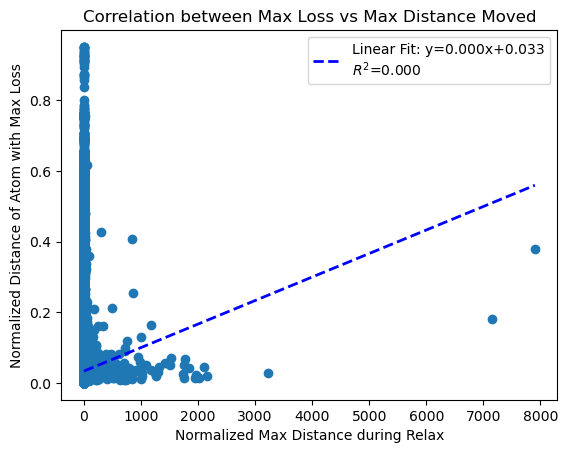

In [28]:
dE = df["dE"]
dF = df["dFmax"]
dS = df["pos_mae"]

print(dE)
print(dF)

print(max(dE))


# Compute linear regression
slope, intercept, r_value, p_value, std_err = stats.linregress(dF, dS)
r_squared = r_value**2

# Generate regression line
x_reg = np.linspace(dF.min(), dF.max(), 100)
y_reg = slope * x_reg + intercept

plt.plot(x_reg, y_reg, color="blue", linewidth=2, linestyle="--", 
         label=f"Linear Fit: y={slope:.3f}x+{intercept:.3f}\n$R^2$={r_squared:.3f}")
plt.xlabel("Normalized Max Distance during Relax")
plt.ylabel("Normalized Distance of Atom with Max Loss")
plt.title("Correlation between Max Loss vs Max Distance Moved")
plt.legend()

plt.scatter(dF, dS)